# TBATS

Un dels reptes d'aquest dataset és conciliar tres fenòmens alhora: una tendència creixent (accelerada pel MOVES III a partir de 2021), una estacionalitat anual estable i una variança que creix amb el nivell de la sèrie — les tecnologies en expansió oscil·len cada cop més en termes absoluts. L'anàlisi BoxCox de l'EDA va recomanar una transformació arrel quadrada (λ≈0.5), cosa que ja apuntava cap a un model que estabilitzés la variança de forma automàtica.

TBATS (Trigonometric seasonality, Box-Cox transformation, ARMA errors, Trend, Seasonal) ha estat dissenyat exactament per a aquest tipus de situació. La transformació Box-Cox s'estima automàticament per a cada sèrie, sense que l'usuari hagi d'escollir λ manualment. La tendència s'estima amb amortiment opcional (`use_damped_trend=True`), cosa que evita extrapolacions massa agressives a llarg termini. L'estacionalitat es representa amb harmònics de Fourier, que capturen la forma estacional de manera suau i contínua. Els errors ARMA absorbeixen l'autocorrelació residual que pugui quedar un cop modelada la tendència i l'estacionalitat.

En comparació amb AutoSARIMA, TBATS no requereix especificar ordres de diferenciació ni decidir si cal transformar la sèrie: tot s'estima automàticament per màxima versemblança. Esperem que sigui especialment competitiu en les tecnologies amb variança més heteroscedàstica (Elèctric, Gasolina/Elèctric Endollable), on AutoSARIMA podria tenir dificultats addicionals.

> Prerequisit: executar `data_preparation.ipynb` primer.

In [1]:
import sys
sys.path.insert(0, '../../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from features import TECNOLOGIES_MODELITZABLES
from evaluation import compute_metrics
from plotting import format_ts_ax

DATA_DIR    = Path('../../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']

In [2]:
try:
    from tbats import TBATS
    print('tbats ja instal·lat')
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'tbats', '-q'])
    from tbats import TBATS
    print('tbats instal·lat correctament')

tbats ja instal·lat


In [3]:
pivot_train = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)
print(f'Train: {pivot_train.index[0].date()} → {pivot_train.index[-1].date()} ({len(pivot_train)} mesos)')
print(f'Test:  {pivot_test.index[0].date()}  → {pivot_test.index[-1].date()}  ({len(pivot_test)} mesos)')

Train: 2017-01-01 → 2024-12-01 (96 mesos)
Test:  2025-01-01  → 2025-12-01  (12 mesos)


## 1. Entrenament TBATS per tecnologia


In [4]:
H = len(pivot_test)

tbats_models     = {}
forecast_records = []
metrics_records  = []

print('Ajustant TBATS per tecnologia (pot trigar uns minuts)...')
for tech in TECNOLOGIES:
    y_train = pivot_train[tech].dropna().values
    y_test  = pivot_test[tech].values

    estimator = TBATS(
        seasonal_periods=[12],
        use_box_cox=True,
        use_trend=True,
        use_damped_trend=True,
        n_jobs=1,
    )
    fitted = estimator.fit(y_train)
    y_pred = np.maximum(fitted.forecast(steps=H), 0)
    tbats_models[tech] = fitted

    m = compute_metrics(y_test, y_pred, y_train)
    m.update({'Tecnologia': tech, 'Model': 'TBATS'})
    metrics_records.append(m)
    print(f'  {tech:35s}: RMSE={m["RMSE"]:.0f}, MAPE={m["MAPE"]:.1f}%')

    for i, date in enumerate(pivot_test.index):
        forecast_records.append({
            'date': date, 'Tecnologia': tech, 'Model': 'TBATS',
            'predicted': y_pred[i], 'actual': y_test[i]
        })

df_metrics   = pd.DataFrame(metrics_records)
df_forecasts = pd.DataFrame(forecast_records)

Ajustant TBATS per tecnologia (pot trigar uns minuts)...


  Elèctric                           : RMSE=561, MAPE=24.7%


  Gasolina Mild Hybrid               : RMSE=235, MAPE=9.4%


  Gasolina/Elèctric                  : RMSE=247, MAPE=8.2%


  Gasolina/Elèctric Endollable       : RMSE=669, MAPE=42.5%


  Diesel Mild Hybrid                 : RMSE=40, MAPE=11.7%


  Diesel/Elèctric Endollable         : RMSE=21, MAPE=35.6%


  Total                              : RMSE=1159, MAPE=11.9%


## 2. Paràmetres seleccionats per TBATS


In [5]:
params_rows = []
for tech, fitted in tbats_models.items():
    p = fitted.params
    ar = getattr(p, 'ar_coefficients', None)
    ma = getattr(p, 'ma_coefficients', None)
    params_rows.append({
        'Tecnologia':  tech,
        'Box-Cox λ':   round(p.box_cox_lambda, 3) if p.box_cox_lambda is not None else 'No',
        'Trend':       'Sí' if p.alpha is not None else 'No',
        'Damped':      'Sí' if p.phi is not None else 'No',
        'AR':          len(ar) if ar is not None else 0,
        'MA':          len(ma) if ma is not None else 0,
    })
pd.DataFrame(params_rows).set_index('Tecnologia')

,Box-Cox λ,Trend,Damped,AR,MA
Tecnologia,,,,,
Elèctric,0.265,Sí,Sí,0,0
Gasolina Mild Hybrid,No,Sí,Sí,0,0
Gasolina/Elèctric,0.78,Sí,Sí,0,0
Gasolina/Elèctric Endollable,0.283,Sí,Sí,0,0
Diesel Mild Hybrid,No,Sí,Sí,0,0
Diesel/Elèctric Endollable,No,Sí,Sí,0,0
Total,0.683,Sí,Sí,0,0


## 3. Mètriques sobre el test (2025)


In [6]:
print('Mètriques TBATS:')
df_metrics.set_index('Tecnologia')[['RMSE', 'MAE', 'MAPE', 'MASE']].round(2)

Mètriques TBATS:


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Elèctric,561.01,466.75,24.70,1.41
Gasolina Mild Hybrid,234.53,178.03,9.40,0.68
Gasolina/Elèctric,246.97,190.29,8.23,0.67
Gasolina/Elèctric Endollable,668.74,599.20,42.54,4.65
Diesel Mild Hybrid,40.04,32.83,11.69,0.54
Diesel/Elèctric Endollable,21.23,17.27,35.57,2.08
Total,1158.85,982.76,11.89,1.13


## 4. Visualització 


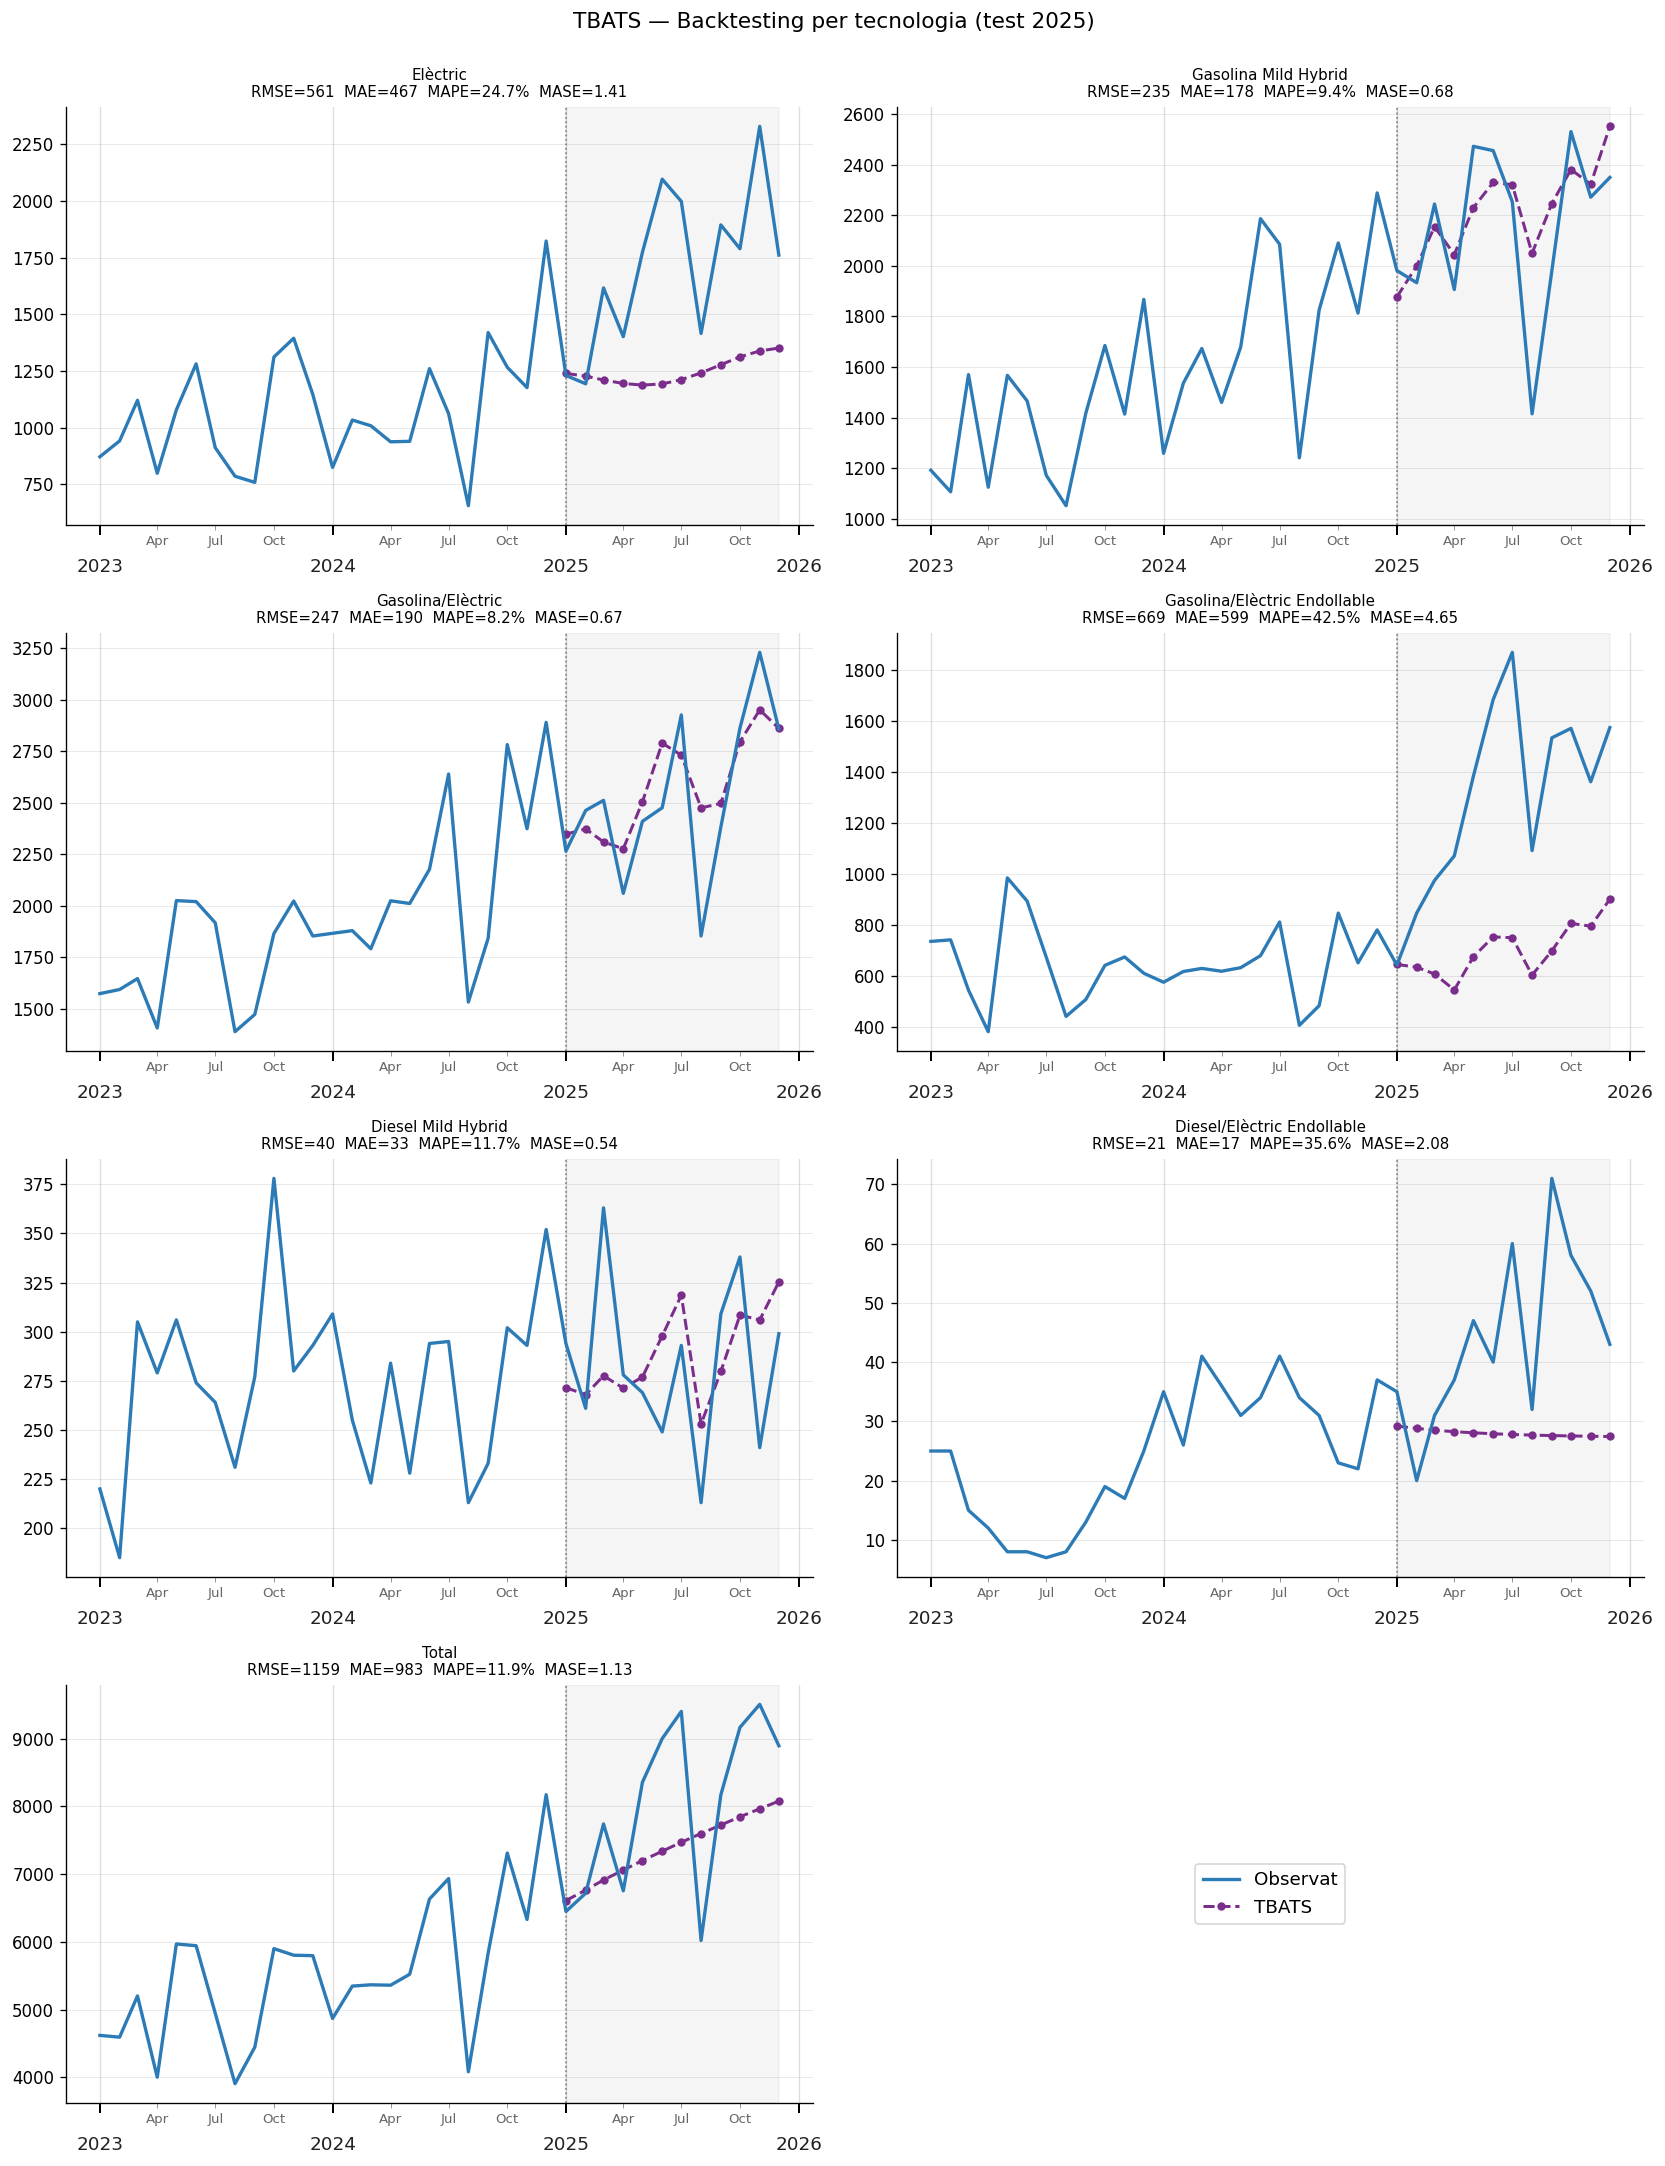

In [7]:
from plotting import plot_backtest_per_tech

plot_backtest_per_tech(
    pivot_train, pivot_test, df_forecasts, df_metrics,
    tecnologies=TECNOLOGIES, model_name='TBATS',
    save_path=FIGURES_DIR / 'fig_tbats_backtest_per_tech.png',
    color_pred='#7b2d8b',
)
plt.show()

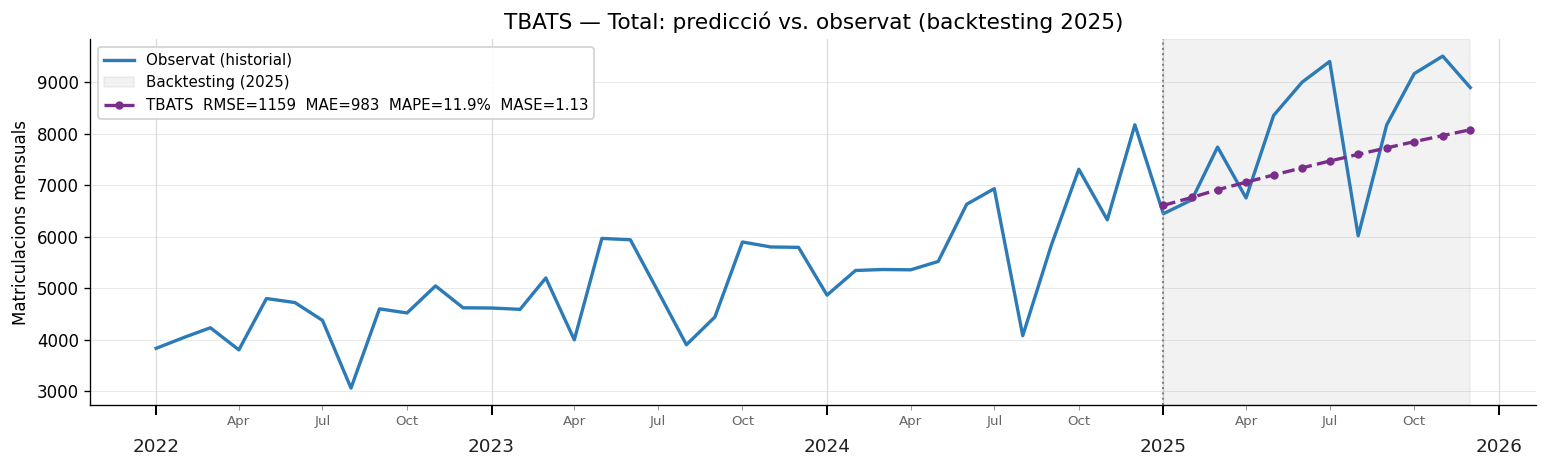

In [8]:
tech = 'Total'
sub = df_forecasts[df_forecasts['Tecnologia'] == tech].sort_values('date')

fig, ax = plt.subplots(figsize=(13, 4))

y_train_plot = pivot_train[tech].iloc[-36:]
y_test_plot  = pivot_test[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, label='Observat (historial)')

ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.10, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1.2)

m_total = df_metrics[df_metrics['Tecnologia'] == tech].iloc[0]
label = (f'TBATS  RMSE={m_total["RMSE"]:.0f}  MAE={m_total["MAE"]:.0f}  '
         f'MAPE={m_total["MAPE"]:.1f}%  MASE={m_total["MASE"]:.2f}')
ax.plot(pd.to_datetime(sub['date']), sub['predicted'],
        color='#7b2d8b', lw=2, ls='--', marker='o', ms=4, label=label)

ax.set_title(f'TBATS — {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=9, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_13_tbats_total.png', bbox_inches='tight')
plt.show()

## 5. Walk-forward validation (rolling-origin)

Replicació del backtest amb 13 origins per sèrie (`initial=60`, `step=3`, `horizon=12`). Cost aproximat: ~30s per fold × 13 folds × 7 tecnologies ≈ 45 minuts.

In [9]:
from evaluation import walk_forward_cv_full

pivot_full = pd.concat([pivot_train, pivot_test]).sort_index()

def tbats_fn(train_series):
    est = TBATS(seasonal_periods=[12], use_box_cox=True, use_trend=True,
                use_damped_trend=True, n_jobs=1)
    fitted = est.fit(train_series.values)
    return np.maximum(fitted.forecast(steps=H), 0)

import time
wfv_metric_rows  = []
wfv_forecast_rows = []
print('Walk-forward TBATS (initial=60, step=3, horizon=12)...')
t0 = time.time()
for tech in TECNOLOGIES:
    t_start = time.time()
    series = pivot_full[tech].dropna()
    m_df, f_df = walk_forward_cv_full(series, tbats_fn, initial=60, step=3, horizon=H)
    m_df['Tecnologia'] = tech
    m_df['Model']      = 'TBATS'
    f_df['Tecnologia'] = tech
    f_df['Model']      = 'TBATS'
    wfv_metric_rows.append(m_df)
    wfv_forecast_rows.append(f_df)
    mase_mean = m_df['MASE'].mean() if 'MASE' in m_df.columns else float('nan')
    print(f'  {tech:35s}: {len(m_df)} folds, MASE_mean={mase_mean:.2f}, {time.time()-t_start:.0f}s')
print(f'Total: {(time.time()-t0)/60:.1f} min')

df_wfv_metrics   = pd.concat(wfv_metric_rows, ignore_index=True)
df_wfv_forecasts = pd.concat(wfv_forecast_rows, ignore_index=True)

wfv_agg = (df_wfv_metrics.dropna(subset=['MASE'])
           .groupby('Tecnologia')[['RMSE', 'MAE', 'MAPE', 'MASE']]
           .mean().round(2).reset_index())
print('\nMitjana WFV per tecnologia:')
display(wfv_agg.set_index('Tecnologia'))

Walk-forward TBATS (initial=60, step=3, horizon=12)...


  Elèctric                           : 13 folds, MASE_mean=0.78, 292s


  Gasolina Mild Hybrid               : 13 folds, MASE_mean=0.86, 58s


  Gasolina/Elèctric                  : 13 folds, MASE_mean=1.11, 172s


  Gasolina/Elèctric Endollable       : 13 folds, MASE_mean=1.81, 131s


  Diesel Mild Hybrid                 : 13 folds, MASE_mean=0.64, 31s


  Diesel/Elèctric Endollable         : 13 folds, MASE_mean=1.54, 31s


  Total                              : 13 folds, MASE_mean=1.00, 176s
Total: 14.9 min

Mitjana WFV per tecnologia:


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Diesel Mild Hybrid,51.43,41.75,16.41,0.64
Diesel/Elèctric Endollable,12.74,10.71,52.89,1.54
Elèctric,337.87,277.86,23.55,0.78
Gasolina Mild Hybrid,259.35,207.93,13.70,0.86
Gasolina/Elèctric,344.17,283.06,14.37,1.11
Gasolina/Elèctric Endollable,268.23,224.57,28.02,1.81
Total,1045.52,854.72,15.17,1.00


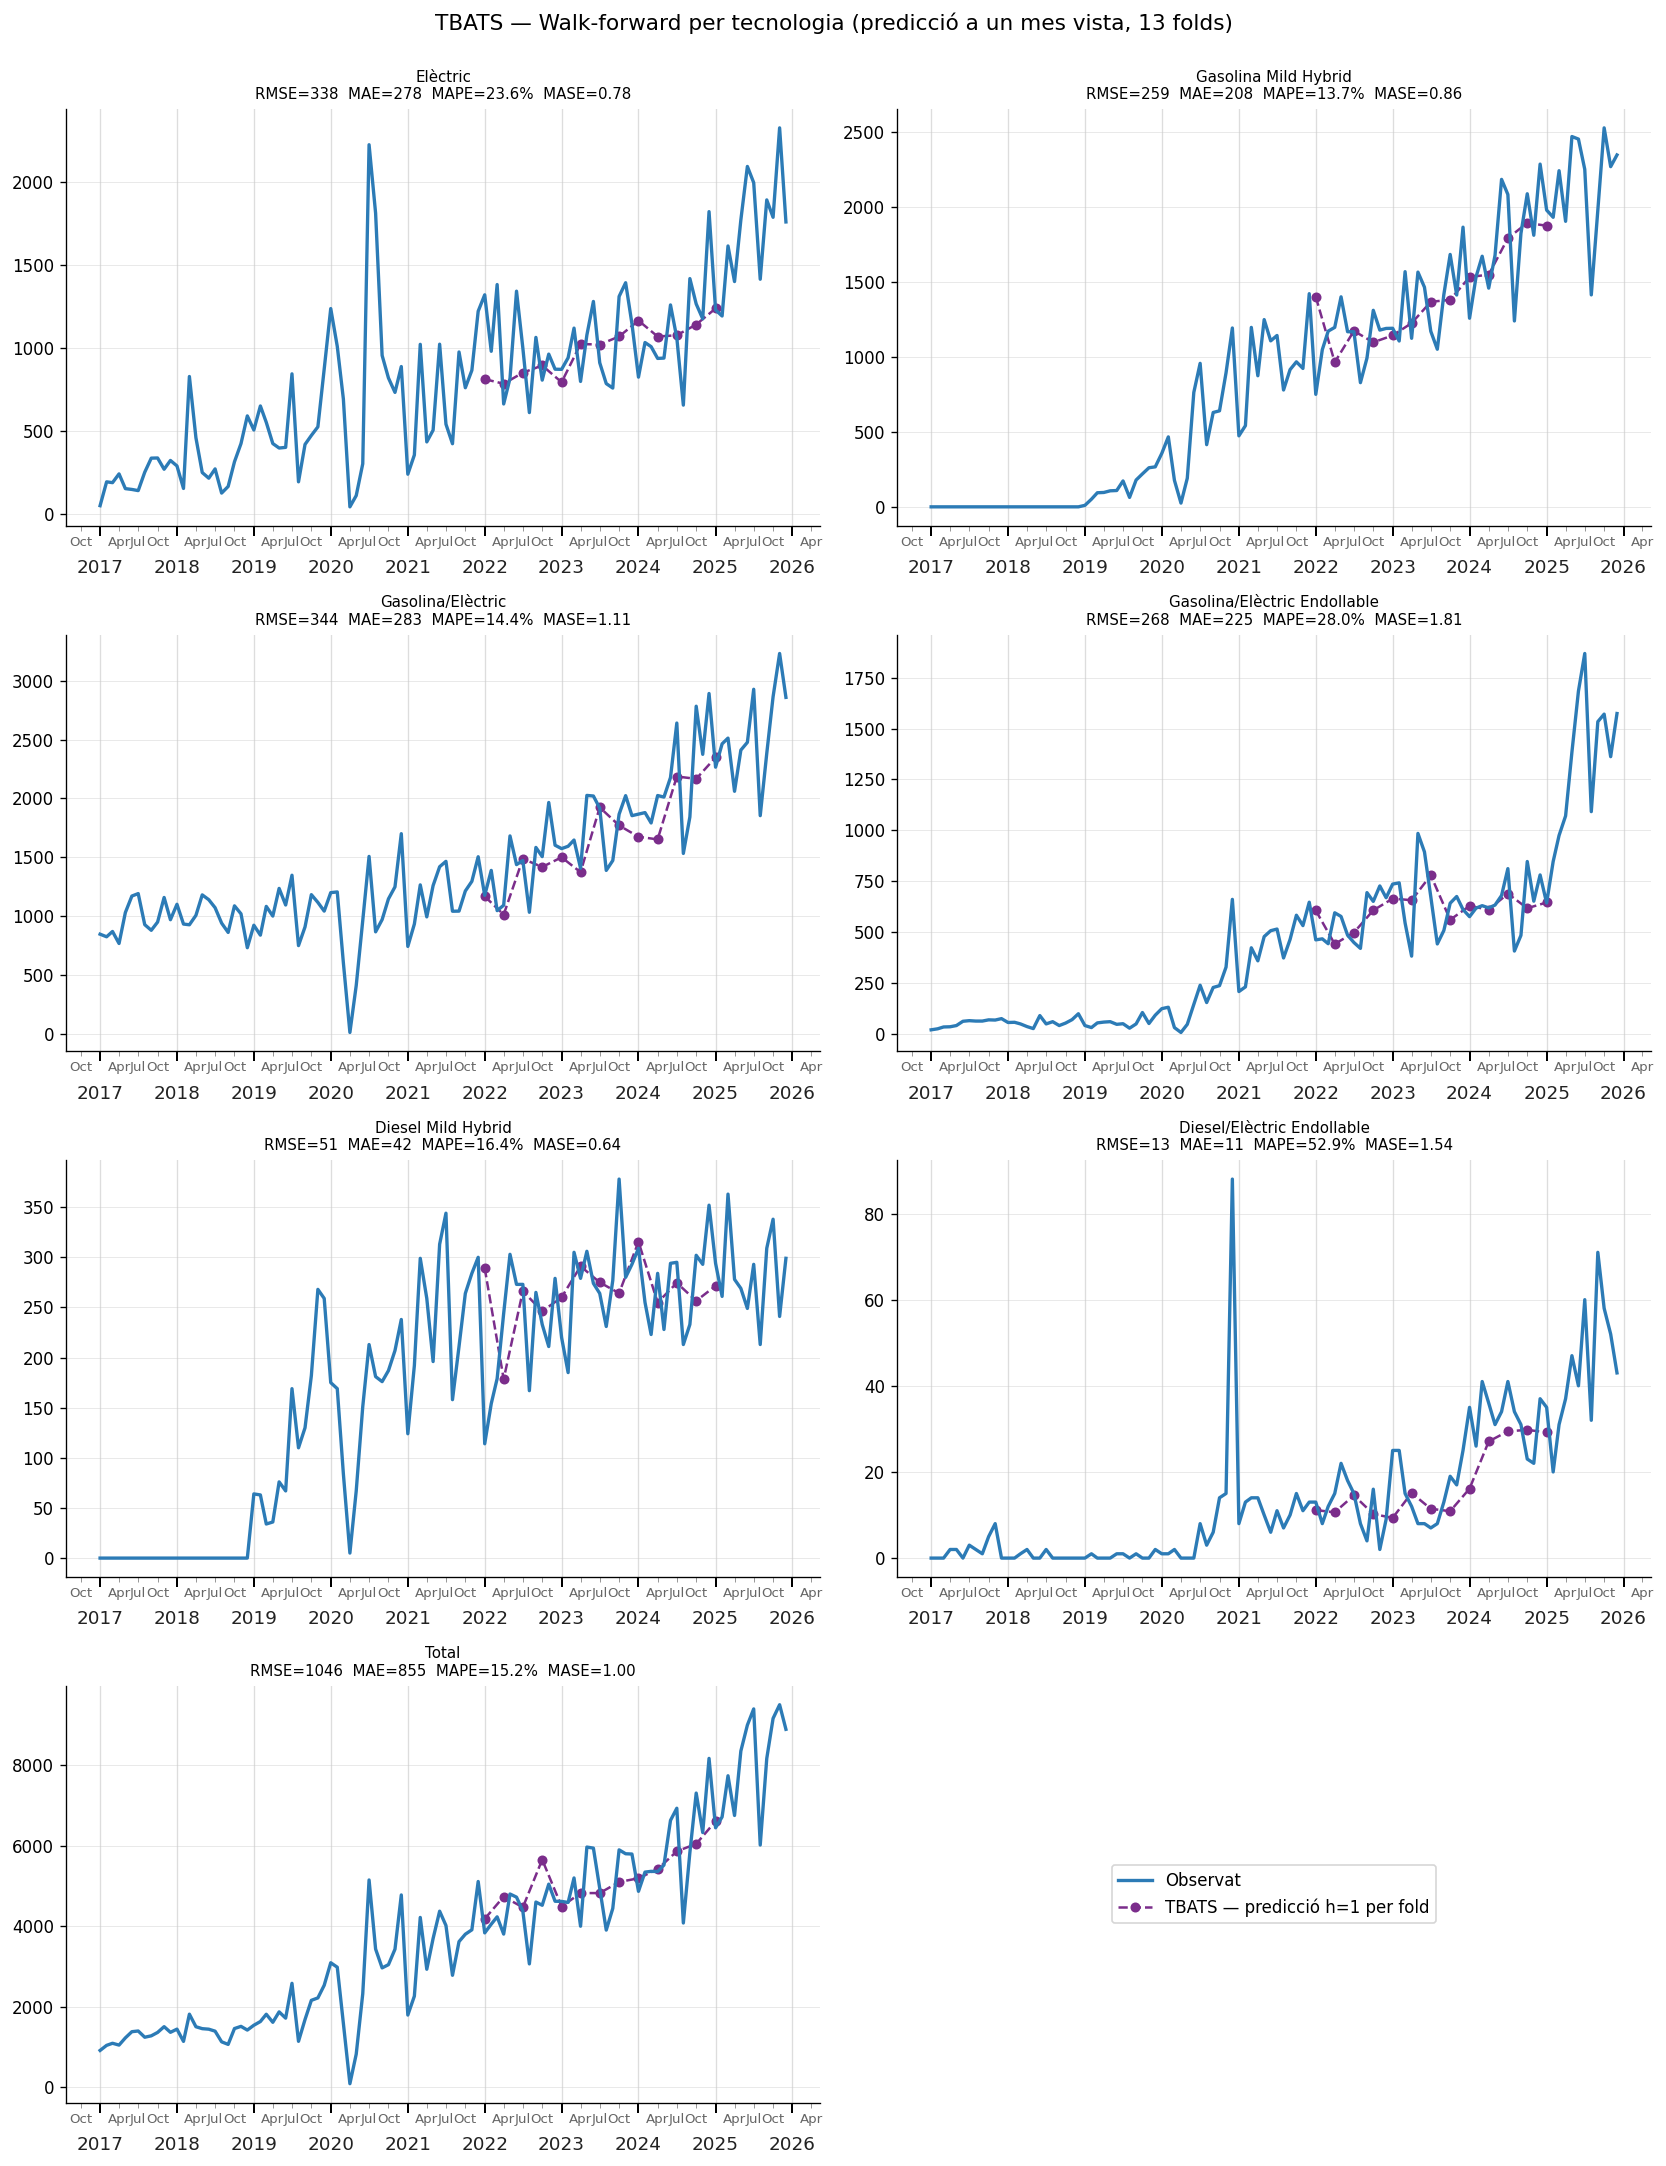

In [10]:
from plotting import plot_wfv_per_tech

plot_wfv_per_tech(
    pivot_full, df_wfv_forecasts, wfv_agg,
    tecnologies=TECNOLOGIES, model_name='TBATS',
    save_path=FIGURES_DIR / 'fig_tbats_wfv_per_tech.png',
    color_pred='#7b2d8b',
)
plt.show()

## 6. Guardar resultats


In [11]:
df_forecasts.to_csv(RESULTS_DIR / 'tbats_forecasts.csv', index=False)
df_metrics.to_csv(RESULTS_DIR / 'tbats_metrics.csv', index=False)
df_wfv_metrics.to_csv(RESULTS_DIR / 'tbats_wfv_metrics.csv', index=False)
df_wfv_forecasts.to_csv(RESULTS_DIR / 'tbats_wfv_forecasts.csv', index=False)
print('Guardats:')
print('  tbats_forecasts.csv, tbats_metrics.csv')
print('  tbats_wfv_metrics.csv, tbats_wfv_forecasts.csv')

Guardats:
  tbats_forecasts.csv, tbats_metrics.csv
  tbats_wfv_metrics.csv, tbats_wfv_forecasts.csv
